# Titanic: Logistic Regression

Train Logistic Regression, evaluate survival predictions, and save the results. Run cells from top to bottom. The other model notebook uses exactly the same preparation and passenger split.

Compare the original scikit-learn estimator with an explicit NumPy implementation.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd()
if not (ROOT / "data" / "data_preparation.py").is_file():
    ROOT = ROOT.parent  # supports a kernel started in models/
sys.path.insert(0, str(ROOT))
from data.data_preparation import load_data, prepare_data

OUTPUT = ROOT / "data" / "output"
GRAPHS = OUTPUT / "graphs"
GRAPHS.mkdir(parents=True, exist_ok=True)

## 2. Inspect and prepare data

`data/data_preparation.py` loads the original input and the fixed split, fills missing values using training medians/modes, encodes training categories, and scales numeric features using training statistics only.

In [2]:
frame = load_data()
print("Input shape:", frame.shape)
print("Missing values:\n", frame.isna().sum())
print("Duplicate rows:", frame.duplicated().sum())
print("Survival counts:\n", frame.Survived.value_counts())
X_train, X_test, y_train, y_test = prepare_data()
print("Training records:", len(X_train), "| Test records:", len(X_test))
print("Prepared columns:", X_train.columns.tolist())

Input shape: (891, 12)
Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0
Survival counts:
 Survived
0    549
1    342
Name: count, dtype: int64
Training records: 712 | Test records: 179
Prepared columns: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## 3. Train with scikit-learn

The baseline uses LogisticRegression(C=1) with the default L2 penalty and L-BFGS solver.

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model_name = 'Logistic Regression'
file_stem = 'logistic_regression'
model.fit(X_train, y_train)
print(model_name, "training complete")

Logistic Regression training complete


## 4. Implement with NumPy

Use a stable sigmoid and gradient descent on L2-regularized binary cross-entropy. The intercept is not penalized; stopping uses training gradients only.

In [4]:
class LogisticRegressionNumPy:
    def __init__(self, C=1.0, learning_rate=0.1, max_iter=50000, tolerance=1e-7):
        self.C = C
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.tolerance = tolerance

    @staticmethod
    def sigmoid(z):
        return np.exp(-np.logaddexp(0, -z))

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.classes_ = np.unique(y)
        if not np.array_equal(self.classes_, [0, 1]):
            raise ValueError("Expected binary labels 0 and 1")
        n = len(y)
        self.weights_ = np.zeros(X.shape[1])
        self.bias_ = 0.0
        self.loss_history_ = []
        for iteration in range(self.max_iter):
            z = X @ self.weights_ + self.bias_
            error = self.sigmoid(z) - y
            # Match the C=1 L2 objective used by the library baseline.
            weight_gradient = X.T @ error / n + self.weights_ / (self.C * n)
            bias_gradient = error.mean()
            loss = np.mean(np.logaddexp(0, z) - y * z)
            loss += self.weights_ @ self.weights_ / (2 * self.C * n)
            self.loss_history_.append(float(loss))
            self.gradient_norm_ = max(np.abs(weight_gradient).max(), abs(bias_gradient))
            if self.gradient_norm_ <= self.tolerance:
                break
            self.weights_ -= self.learning_rate * weight_gradient
            self.bias_ -= self.learning_rate * bias_gradient
        self.n_iter_ = iteration + 1
        if self.gradient_norm_ > self.tolerance:
            raise RuntimeError("Gradient descent did not converge; inspect training loss")
        return self

    def predict_proba(self, X):
        positive = self.sigmoid(np.asarray(X, dtype=float) @ self.weights_ + self.bias_)
        return np.column_stack([1 - positive, positive])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


numpy_model = LogisticRegressionNumPy().fit(X_train, y_train)
model_variants = {"Logistic Regression (scikit-learn)": model,
                  "Logistic Regression (NumPy)": numpy_model}
print("Gradient descent iterations:", numpy_model.n_iter_)
print("Final training loss:", numpy_model.loss_history_[-1])
print("Maximum absolute training gradient:", numpy_model.gradient_norm_)

Gradient descent iterations: 19158
Final training loss: 0.45219618013160673
Maximum absolute training gradient: 9.994337846208623e-08


### Training loss

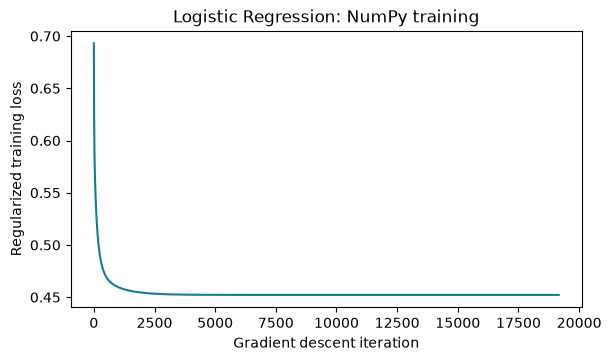

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.plot(np.arange(1, numpy_model.n_iter_ + 1), numpy_model.loss_history_, color="#147d92")
ax.set(xlabel="Gradient descent iteration", ylabel="Regularized training loss",
       title="Logistic Regression: NumPy training")
fig.savefig(GRAPHS / "logistic_regression_training_loss.png", dpi=150)
plt.show()
plt.close(fig)

## 5. Evaluate both implementations

Survival is class 1. Precision, recall and F1 refer to survivors. ROC-AUC and log-loss use survival probabilities; predictions use threshold 0.5.

In [6]:
evaluations = {}
for name, estimator in model_variants.items():
    probability = estimator.predict_proba(X_test)[:, list(estimator.classes_).index(1)]
    prediction = (probability >= 0.5).astype(int)
    scores = {
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Log-loss": log_loss(y_test, np.column_stack([1-probability, probability]), labels=[0, 1]),
    }
    evaluations[name] = {
        "metrics": {key: float(value) for key, value in scores.items()},
        "confusion_matrix": confusion_matrix(y_test, prediction, labels=[0, 1]).tolist(),
        "training_records": len(y_train), "test_records": len(y_test),
    }
print(pd.DataFrame({name: result["metrics"] for name, result in evaluations.items()}).T.round(6))
majority = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority))
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")
probability_gap = np.max(np.abs(model.predict_proba(X_test) - numpy_model.predict_proba(X_test)))
print(f"Maximum library/NumPy probability difference: {probability_gap:.8f}")

                                    Accuracy  Precision    Recall        F1  \
Logistic Regression (scikit-learn)  0.804469   0.753846  0.720588  0.736842   
Logistic Regression (NumPy)         0.804469   0.753846  0.720588  0.736842   

                                     ROC-AUC  Log-loss  
Logistic Regression (scikit-learn)  0.864997  0.434158  
Logistic Regression (NumPy)         0.864865  0.434034  
Majority-class baseline accuracy: 0.6201
Maximum library/NumPy probability difference: 0.00089202


## 6. Compare confusion matrices

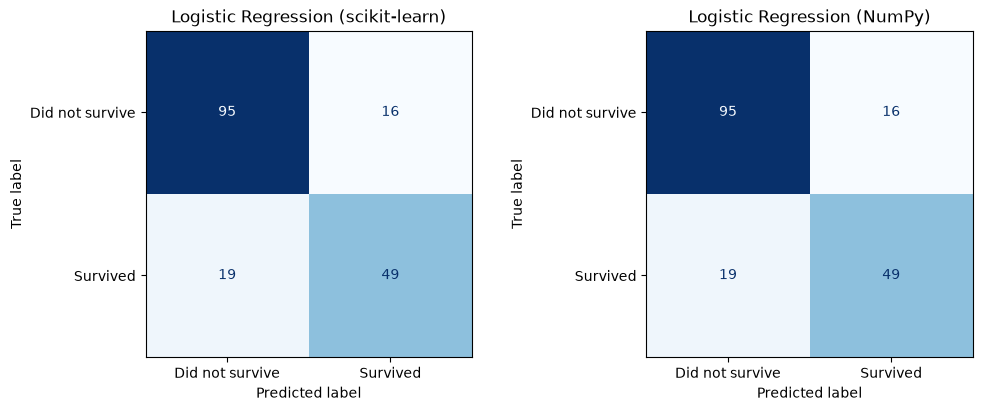

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, result) in zip(axes, evaluations.items()):
    ConfusionMatrixDisplay(np.array(result["confusion_matrix"]),
                           display_labels=["Did not survive", "Survived"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.savefig(GRAPHS / f"{file_stem}_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

## 7. Update the shared results

Keep results for both implementations of this model. Run both notebooks after changing preparation or training code.

In [8]:
metrics_path = OUTPUT / "metrics.json"
saved = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
for old_name in ["Naive Bayes", "Logistic Regression"]:
    saved.pop(old_name, None)
for name, result in evaluations.items():
    result["majority_baseline_accuracy"] = float(baseline_accuracy)
    result["implementation"] = "NumPy" if name.endswith("(NumPy)") else "scikit-learn"
    saved[name] = result
order = ["Naive Bayes (scikit-learn)", "Naive Bayes (NumPy)",
         "Logistic Regression (scikit-learn)", "Logistic Regression (NumPy)"]
saved = {name: saved[name] for name in order if name in saved}
metrics_path.write_text(json.dumps(saved, indent=2) + "\n")
lines = ["# Titanic model metrics", "",
         f"Training records: {len(y_train)}. Test records: {len(y_test)}. Positive class: survived (1).",
         "These are test results from models fitted on the training records.", "",
         "| Model / implementation | Accuracy | Precision | Recall | F1 | ROC-AUC | Log-loss |",
         "| --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for name, result in saved.items():
    values = result["metrics"]
    lines.append("| " + name + " | " + " | ".join(f"{values[key]:.6f}" for key in scores) + " |")
lines += ["", f"Majority-class baseline accuracy: {baseline_accuracy:.4f}.", "",
          "## Confusion matrices", ""]
for family, stem in [("Naive Bayes", "naive_bayes"), ("Logistic Regression", "logistic_regression")]:
    if any(name.startswith(family) for name in saved):
        lines += [f"![{family}: library and NumPy](graphs/{stem}_confusion_matrix.png)", ""]
lines += ["Rows are true labels; columns are predictions, ordered [0, 1].", "",
          "## Implementations", "",
          "The scikit-learn estimators remain as baselines. NumPy model training and prediction are implemented directly in each notebook.",
          "Naive Bayes estimates priors, class means/variances, Gaussian log-likelihoods and normalized probabilities.",
          "NumPy Logistic Regression minimizes mean binary cross-entropy plus ||w||^2/(2*C*n), with an unpenalized intercept.",
          "It uses full-batch gradient descent: C=1, learning rate 0.1, maximum 50,000 steps, gradient tolerance 1e-7.",
          "The library LR baseline uses C=1 with its default L-BFGS solver and max_iter=1000.",
          "Scikit-learn is still used for shared preparation, evaluation metrics and confusion-matrix display.", ""]
if "Logistic Regression (NumPy)" in saved:
    lines += ["![NumPy Logistic Regression training loss](graphs/logistic_regression_training_loss.png)", ""]
lines += ["## Findings", ""]
for family in ["Naive Bayes", "Logistic Regression"]:
    library, manual = family + " (scikit-learn)", family + " (NumPy)"
    if library in saved and manual in saved:
        reference, direct = saved[library]["metrics"], saved[manual]["metrics"]
        lines += [f"{family} accuracy: scikit-learn {reference['Accuracy']:.2%}, NumPy {direct['Accuracy']:.2%}.",
                  f"Log-loss: scikit-learn {reference['Log-loss']:.6f}, NumPy {direct['Log-loss']:.6f}.", ""]
lines += ["All implementations use the same fixed records and training-only preparation. Optimizer convergence is checked on training data; test scores are not used to choose settings.",
          "The test partition was inspected during earlier development; this is a fixed comparison, not a new independent test.",
          "A single historical sample does not establish that one model is universally better.", ""]
(OUTPUT / "metrics.md").write_text("\n".join(lines), encoding="utf-8")
print("Updated metrics.md and metrics.json with both implementations")

Updated metrics.md and metrics.json with both implementations
